# Diagonals and direction: does dog transfer flow into the higher-diagonal model?

Two measurements meet here, both on Pythia-160m **dog** students at **student finetune seed 1**, on the numbers pool `ex10-20_prefix_n100k`.

**The diagonal — a property of ONE model.** `diag_post(m)` = model *m*'s own checkpoint-distill diagonal: a teacher finetuned on `m@step t`, distilled back into `m@step t`, averaged over the five teacher recipes `ep20_lr1e-4_r16a32, ep2_lr5e-4_r32a64, ep7_lr5e-4_r8a8, ep10_lr1e-4_r64a64, ep20_lr1e-4_r8a16` and over the post-cliff steps **115k / 125k / 143k**. A step that does not carry all five recipes is *skipped*, not averaged (it would sit on another scale); `n_steps` records how many were used. Secondary readings: `diag_125k`, `diag_143k`, and `diag_post_seedmean` (ftseeds averaged within a (step, recipe) first).

**The directed arm — a property of an ORDERED pair.** `T(x→y)` = x's ten k-band dog teachers (`run_logs/dog_top10_kband_configs.json`, teacher seed 1) distilled into y on the **core30** design (`run_logs/core30_cells.json`), read against the matched control — the *untuned* x base's numbers pool distilled into y in the **same** student cell, same student seed. Three statistics: `mean_rel` (treatment − control, in units of y's dog test prior; **primary**), `exceed_frac` (share of runs above their own cell's control) and `mean_p` (raw mean treatment p(dog), no control needed). **Dead runs are KEPT** and only counted: a dead label is an outcome of the treatment, so dropping on it would condition on a post-treatment variable.

**The question.** For an unordered pair {x, y} with both directions loaded, is `asym = T(x→y) − T(y→x)` the same sign as `ddiag = diag(y) − diag(x)`? That is `into_higher_diag`: the stronger direction is the one flowing *into* the higher-diagonal model. Pairs are stratified by `relationship` (same-model / cross-data-order / cross-init / cross-both / cross-corpus) because the strata differ by orders of magnitude in effect.

**Flagged assumptions** (also carried per model in `MODELS[...].assumed`, and per pair in the tables' `assumed` column):

- `pr3` — assumed init seed 3 and assumed the original (D0) Pile data order.
- `dclm1` — assumed init seed 1; `dclm1234`/`dclm1` are assumed to share one DCLM data order.
- `ws1` — only 125k and 143k are on disk, so its diagonal is a **two**-step mean (`n_steps = 2`); `ws2`, `ws3` and `dclm1` have **no** diagonal at all and are NaN.
- `pr1234→orig` is **in flight** (partial student and control coverage) — it is reported with status `partial`, never silently dropped.
- The `ws` arms, `orig→wc1` and `dclm1234→dclm1` have **no matched base control** on disk: their control-normalized columns are NaN and only `mean_p` is readable (status `no-control`).
- Nothing is dropped for being unavailable: every ordered pair of the 16 lineages appears in table 2 with a status (`ok` / `partial` / `no-control` / `not-run`).

Inference everywhere treats the **model label** as the exchangeable unit — the arms share endpoints, so permuting arms would be a null the design does not support. Sign agreement is an exact two-sided binomial; every Spearman carries a model-label permutation p (2000 permutations, fixed seed).

## Load

One cached sweep for the checkpoint diagonals, one for the arms (treatment + matched control, ftseed 1, core30).

In [1]:
import json
import pandas as pd
from subliminal_learning.analysis import diagonal_direction as dd
from subliminal_learning.analysis.setup import bootstrap

REPO, OUT = bootstrap()     # repo-anchored: every path below is absolute
DIAG = dd.diagonal_table(dd.load_diagonal_runs(OUT))
TEACHERS = json.loads((REPO / "run_logs/dog_top10_kband_configs.json").read_text())["param_tags"]

In [2]:
CELLS30, CELLS56 = REPO / "run_logs/core30_cells.json", REPO / "run_logs/core56_cells.json"
ARM_PAIRS = dd.arms_on_disk(OUT)
RUNS = dd.load_arm_runs(ARM_PAIRS, TEACHERS, CELLS56, output_root=OUT)   # core56 superset of core30
RUNS30 = RUNS[RUNS.cell.isin(dd.resolve_cells(CELLS30))]
print(f"{len(ARM_PAIRS)} arm trees on disk, {len(RUNS)} runs (core56), {len(RUNS30)} on core30")

pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 6122 rows of 96224 cached (0 added, 0 refreshed, 300 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 859 rows of 96224 cached (0 added, 0 refreshed, 1 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 1929 rows of 96224 cached (0 added, 0 refreshed, 311 inventory paths without a record, 0 unreadable/kept)


... (2 outputs left out)

pile_probe cache: 1680 rows of 96224 cached (0 added, 0 refreshed, 560 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


pile_probe cache: 2240 rows of 96224 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


60 arm trees on disk, 29787 runs (core56), 17301 on core30


## T1. Lineage table

One row per lineage: its taxonomy, its post-cliff diagonal (and rank), and how strong it is as a **sender** and as a **receiver** — the mean of `mean_rel` over the off-diagonal arms it sends / receives, pooled and per relationship stratum. The `x→x` diagonal arms are a reference row set in T2 and never enter a strength.

In [3]:
T1 = dd.lineage_table(DIAG, dd.arm_table(RUNS30, DIAG, CELLS30, on_disk=ARM_PAIRS))
T1.round(3)

,init,order,corpus,tree,assumed,diag_post,n_steps,steps_used,diag_125k,diag_143k,...,send[same-model],recv[same-model],send[cross-data-order],recv[cross-data-order],send[cross-init],recv[cross-init],send[cross-both],recv[cross-both],send[cross-corpus],recv[cross-corpus]
model,,,,,,,,,,,,,,,,,,,,,
orig,orig,D0,Pile,v1.0-orig,,0.724,3,"115k,125k,143k",0.782,0.745,...,0.470,11.321,3.524,10.445,NaN,NaN,0.447,4.308,NaN,NaN
ds1,orig,Dds1,Pile,v1.0-orig,,0.691,3,"115k,125k,143k",0.687,0.664,...,NaN,NaN,13.373,5.239,NaN,NaN,NaN,NaN,NaN,NaN
ds2,orig,Dds2,Pile,v1.0-orig,,0.779,3,"115k,125k,143k",0.821,0.746,...,NaN,NaN,5.132,11.197,NaN,NaN,NaN,NaN,NaN,NaN
ds3,orig,Dds3,Pile,v1.0-orig,,0.638,3,"115k,125k,143k",0.616,0.645,...,NaN,NaN,12.457,7.603,NaN,NaN,NaN,NaN,NaN,NaN
ws1,orig,D0,Pile,v1.0-orig,,0.760,2,"125k,143k",0.776,0.744,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ws2,orig,D0,Pile,v1.0-orig,,NaN,0,,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ws3,orig,D0,Pile,v1.0-orig,,NaN,0,,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fs1,s1,Dfs1,Pile,v1.0-orig,,0.665,3,"115k,125k,143k",0.659,0.776,...,NaN,NaN,NaN,NaN,NaN,NaN,1.264,0.442,NaN,NaN
fs2,s2,Dfs2,Pile,v1.0-orig,,0.559,3,"115k,125k,143k",0.552,0.534,...,NaN,NaN,NaN,NaN,NaN,NaN,1.834,0.412,NaN,NaN


## T2. Ordered-arm table

Every ordered pair of the 16 lineages, sorted by relationship then sender. `coverage` = design cells reached / 30. `status`: `ok` (full core30 coverage with a control), `partial` (fewer than 30 design cells), `no-control` (+`+partial`), `no-runs` (a tree exists but carries nothing at these ten teachers on this design — e.g. `ds1→ds1`, run at another cell set) and `not-run` (no tree at all). `mean_p` is the raw mean treatment p(dog) and is defined even without a control. `n_dead` is NaN where the receiver has no anchored pp1 cut (unlabelled is not "0 dead"). The `core56` column repeats `mean_rel` on the wider design for the arms that cover it — a robustness read, not the primary.

In [4]:
T2 = dd.arm_table(RUNS30, DIAG, CELLS30, on_disk=ARM_PAIRS)
T2["mean_rel_core56"] = dd.arm_table(RUNS, DIAG, CELLS56, on_disk=ARM_PAIRS).set_index(["sender", "receiver"]).mean_rel.reindex(
    list(zip(T2.sender, T2.receiver))).to_numpy()
T2[T2.status != "not-run"].round(3)

,sender,receiver,relationship,tree_differs,status,n_runs,n_cells,coverage,mean_rel,mean_abs,exceed_frac,mean_p,n_dead,diag_sender,diag_receiver,has_control,mean_rel_core56
0,orig,pr1234,same-model,True,ok,300,30,1.000,0.470,0.006,0.697,0.015,NaN,0.724,0.255,True,0.470
1,orig,ws1,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.023,51.0,0.724,0.760,False,NaN
2,orig,ws2,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.038,15.0,0.724,NaN,False,NaN
3,orig,ws3,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.020,2.0,0.724,NaN,False,NaN
4,pr1234,orig,same-model,True,ok,300,30,1.000,11.321,0.110,0.910,0.131,NaN,0.255,0.724,True,11.321
8,ws1,orig,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.037,41.0,0.760,0.724,False,NaN
10,ws1,ws2,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.045,14.0,0.760,NaN,False,NaN
11,ws1,ws3,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.084,13.0,0.760,NaN,False,NaN
12,ws2,orig,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.084,26.0,NaN,0.724,False,NaN
14,ws2,ws1,same-model,False,no-control,300,30,1.000,NaN,NaN,NaN,0.095,37.0,NaN,0.760,False,NaN


## T3. Pair asymmetry

One row per unordered pair with **both** directions loaded and **both** diagonals present. Both directions are scored on **identical cells** — the intersection of the cells the two directions reach, further restricted to cells with a control on both sides for `mean_rel` and `exceed_frac` — so an asymmetry can never be a difference in which cells happened to land. `into_higher_diag` = `sign(asym) == sign(ddiag)`.

In [5]:
T3 = dd.pair_table(RUNS30, DIAG)
T3.round(3)

,x,y,relationship,tree_differs,assumed,n_cells,n_cells_ctrl,diag_x,diag_y,ddiag,...,asym_mean_rel,into_higher_diag_mean_rel,exceed_frac_xy,exceed_frac_yx,asym_exceed_frac,into_higher_diag_exceed_frac,mean_p_xy,mean_p_yx,asym_mean_p,into_higher_diag_mean_p
0,orig,ds1,cross-data-order,False,,30,30,0.724,0.691,-0.033,...,-9.699,True,0.713,0.887,-0.173,True,0.050,0.138,-0.088,True
1,orig,ds2,cross-data-order,False,,30,30,0.724,0.779,0.055,...,0.586,True,0.723,0.820,-0.097,False,0.063,0.042,0.021,True
2,orig,ds3,cross-data-order,False,,30,30,0.724,0.638,-0.086,...,-11.649,True,0.843,0.777,0.067,False,0.044,0.196,-0.152,True
3,orig,ws1,same-model,False,,30,0,0.724,0.760,0.036,...,NaN,None,NaN,NaN,NaN,None,0.023,0.037,-0.014,False
4,orig,fs1,cross-both,False,,30,30,0.724,0.665,-0.059,...,-3.012,True,0.513,0.780,-0.267,True,0.010,0.044,-0.033,True
5,orig,fs2,cross-both,False,,30,30,0.724,0.559,-0.165,...,-1.624,True,0.753,0.687,0.067,False,0.008,0.041,-0.033,True
6,orig,fs3,cross-both,False,,30,30,0.724,0.842,0.118,...,-6.946,False,0.470,0.843,-0.373,False,0.020,0.086,-0.066,False
7,orig,wc1,cross-init,True,,30,0,0.724,0.756,0.032,...,NaN,None,NaN,NaN,NaN,None,0.002,0.006,-0.004,False
8,orig,pr1234,same-model,True,,30,30,0.724,0.255,-0.469,...,-10.851,True,0.697,0.910,-0.213,True,0.015,0.131,-0.116,True
9,ds1,ds2,cross-data-order,False,,30,30,0.691,0.779,0.088,...,9.290,True,0.973,0.867,0.107,True,0.173,0.078,0.095,True


Per relationship stratum and pooled: the exact two-sided binomial test of the agreement count (p = ½) and Spearman(`asym`, `ddiag`) with its model-label permutation p, for all three statistics.

In [6]:
T3_TESTS = dd.direction_tests(T3, DIAG, n_perm=2000, seed=0)
T3_TESTS.round(4)

,statistic,stratum,n_pairs,n_agree,binom_p,rho,perm_p
0,mean_rel,same-model,1,1,1.0000,NaN,NaN
1,mean_rel,cross-data-order,6,5,0.2188,0.6000,0.5077
2,mean_rel,cross-init,2,1,1.0000,NaN,NaN
3,mean_rel,cross-both,6,5,0.2188,0.4857,0.5527
4,mean_rel,cross-corpus,1,0,1.0000,NaN,NaN
5,mean_rel,POOLED,16,12,0.0768,0.3529,0.4203
6,exceed_frac,same-model,1,1,1.0000,NaN,NaN
7,exceed_frac,cross-data-order,6,3,1.0000,0.0857,0.9735
8,exceed_frac,cross-init,2,1,1.0000,NaN,NaN
9,exceed_frac,cross-both,6,2,0.6875,-0.2571,0.6407


## T4. Sender vs receiver

Does the arm effect track the **sender's** diagonal or the **receiver's**? Per stratum, Spearman of `mean_rel` against each endpoint's diagonal with the model-label permutation p; the `POOLED` rows use the **stratum-demeaned** statistic, so a stratum's overall level cannot masquerade as a diagonal effect. The rank OLS `rank(T) ~ rank(diag_sender) + rank(diag_receiver) + C(stratum)` puts both in one fit — read its coefficients, and take the permutation p's above as the inference. The per-model view scores each lineage by its mean stratum-demeaned effect in each role.

In [7]:
T4, OLS = dd.role_tests(T2, DIAG, n_perm=2000, seed=0)
SCORES, ROLE_TESTS = dd.per_model_roles(T2, DIAG, n_perm=2000, seed=0)
display(T4.round(4), pd.DataFrame(OLS).T.round(3), SCORES.round(3), ROLE_TESTS.round(4))

,stratum,role,n_arms,rho,perm_p
0,cross-data-order,sender,12,-0.7341,0.2474
1,cross-data-order,receiver,12,0.3239,0.3148
2,cross-init,sender,4,0.4000,0.7721
3,cross-init,receiver,4,0.4000,0.7751
4,cross-both,sender,12,-0.2159,0.6037
5,cross-both,receiver,12,0.4318,0.4988
6,POOLED,sender,32,-0.4174,0.2199
7,POOLED,receiver,32,0.2342,0.3908


,coef,se,t,p
Intercept,10.174,4.223,2.409,0.024
C(stratum)[T.cross-corpus],-9.010,5.417,-1.663,0.109
C(stratum)[T.cross-data-order],12.449,2.272,5.478,0.000
C(stratum)[T.cross-init],-3.305,3.644,-0.907,0.373
C(stratum)[T.same-model],6.575,4.389,1.498,0.147
ds,-0.088,0.131,-0.670,0.509
dr,0.223,0.131,1.697,0.102
_n,32.000,32.000,32.000,32.000
_r2,0.719,0.719,0.719,0.719


,diag_post,diag_rank,sender_score,n_send,receiver_score,n_recv
model,,,,,,
orig,0.724,5.0,-3.447,7,2.724,7
ds1,0.691,6.0,4.751,3,-3.382,3
ds2,0.779,2.0,-3.490,3,2.576,3
ds3,0.638,8.0,3.835,3,-1.018,3
ws1,0.760,3.0,NaN,0,NaN,0
ws2,NaN,NaN,NaN,0,NaN,0
ws3,NaN,NaN,NaN,0,NaN,0
fs1,0.665,7.0,-0.319,3,-1.141,3
fs2,0.559,10.0,0.251,3,-1.171,3


,role,n_models,rho,perm_p
0,sender,8,-0.3810,0.3603
1,receiver,9,0.3667,0.3353


## F1. Figure

Left: each off-diagonal arm's `mean_rel` against its **receiver's** diagonal, coloured by relationship and sized by the **sender's** diagonal. Right: each pair's asymmetry against `ddiag`, with the two agreeing quadrants shaded.

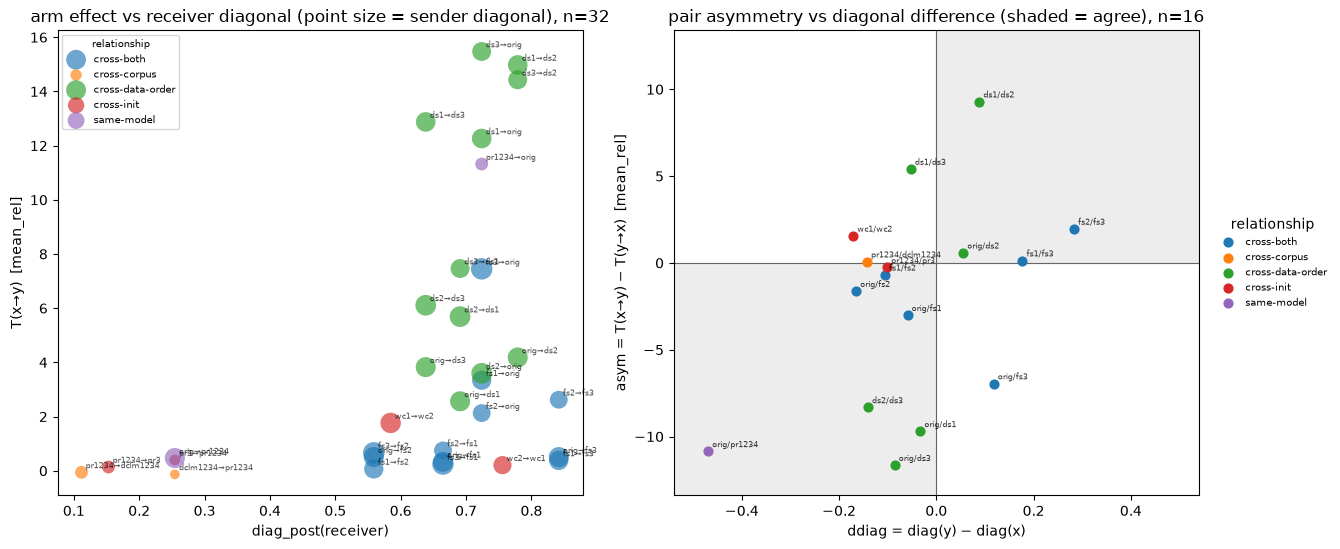

In [8]:
from subliminal_learning.analysis import plots as aplots

FIG, _ = aplots.diagonal_direction_panels(T2, T3)
FIG.savefig(REPO / "notebooks/figures/diagonal_direction_panels.png", dpi=150, bbox_inches="tight")

## Reading

Generated from the frames the cells above just computed, so a re-execution can never leave a stale number behind.

In [9]:
from IPython.display import Markdown, display

display(Markdown(dd.reading(DIAG, T2, T3, T3_TESTS)))

- **Diagonals.** 13 of 16 lineages have a post-cliff diagonal; highest fs3 (0.842), lowest dclm1234 (0.112), spread 0.730.
- **Arms.** 37 complete, 0 partial, 22 without a matched control, 1 with a tree but no run at these teachers, 196 never run.
- **Pairs.** 19 unordered pairs carry both directions and both diagonals.
- **mean_rel** (pooled): 12/16 pairs flow into the higher-diagonal model (binomial p = 0.0768); Spearman(asym, ddiag) = 0.35, label-permutation p = 0.42.
- **exceed_frac** (pooled): 8/16 pairs flow into the higher-diagonal model (binomial p = 1); Spearman(asym, ddiag) = -0.22, label-permutation p = 0.48.
- **mean_p** (pooled): 14/19 pairs flow into the higher-diagonal model (binomial p = 0.0636); Spearman(asym, ddiag) = 0.38, label-permutation p = 0.315.

## 5. Why? — the covariates

Sections 1–4 asked *whether* the direction tracks the diagonal. Sections 5–8 ask **why a model sends or receives well**, on the same design (dog, ftseed 1, core30, dead kept): decompose `T(x→y)` into a sender effect and a receiver effect, then regress those effects on properties of the sender's **number channel** and of the receiver's **damage / dose position**.

Two responses, both on every *complete* (`status == ok`) off-diagonal arm:

- `log_p_rel = log(mean_p / prior(receiver))` — how many times its own untuned dog prior the receiver ends at, logged so the model effects are additive. Positive by construction, and defined without a control.
- `mean_rel` — the control-normalized primary of T2, carried through unchanged.

**Sender covariates** (T5), each a mean over the lineage's ten k-band dog teachers. *Channel:* `pool_entropy_bits` and `pool_top5_mass` (how concentrated the generated number pool is), `pool_tv_to_base` (how far the teacher pool moved off the lineage's own **untuned base** pool) and `carrier_norm = ‖Δ_x‖`, where `Δ_x` = mean teacher unigram − base unigram is the lineage's mean *carrier* over the ints 0–999 (`numbers.pool_stats`). *Containment:* the teacher pile probe `teacher_delta_ce` / `teacher_kl` on the lineage's **native** probe pool — `pp1` for the Pile lineages, `cp1` for the DCLM ones, recorded per row in `probe_pool` and never mixed; the cross-corpus sidecar is `teacher_delta_ce_cross` where it exists (wc, pr, dclm — 10/10 each).

**Receiver covariates** (T6). `ctrl_delta_ce` is the mean pile probe of the receiver's **control** students (untuned sender pools distilled into it on the same cells) — trait-free damage at this dose. Deadness is given under **both** cuts and both are labelled: the flat comparison cut `DEAD_KL_CUT = 4.0` (KL) for every receiver, and the operative **anchored** cut (ΔCE > `Delta_cross`) where an anchor exists — `wc2`, `pr1234` and `pr3` have **no** anchor, so `ctrl_dead_frac_anchored` is NaN there, never a silent fallback. `k_rel_median` is the dose position: the median over the core30 cells of `K/K*`, with `K*` the mean of the receiver's dog arms' `kstar_pooled` from `docs/results/boundary_law_deep_dive_artifacts.json` and K evaluated in the **same** pooled coordinate those were fitted in (b ≈ 0.571, c ≈ −0.078). The boundary-law fits cover only orig / ds / ws / fs receivers, so `k_rel_median` is NaN for wc, pr and dclm — a gap, not a zero.

In [10]:
POOLS = dd.load_pool_unigrams(TEACHERS, output_root=OUT)           # 16 base + 160 teacher pools
CTRL = dd.control_probe_frame(ARM_PAIRS, CELLS30, output_root=OUT)
KSTAR, COORD = dd.load_kstar_arms(REPO / "docs/results/boundary_law_deep_dive_artifacts.json")
print(f"{len(POOLS)} pools, {len(CTRL)} control probes, {len(KSTAR)} K* arms, coordinate {COORD}")

pile_probe cache: 960 rows of 96224 cached (0 added, 0 refreshed, 840 inventory paths without a record, 0 unreadable/kept)
176 pools, 960 control probes, 38 K* arms, coordinate {'b': 0.5708954161201133, 'c': -0.07788200148558873}


In [11]:
T5 = dd.sender_covariates(POOLS, TEACHERS, output_root=OUT)
T6 = dd.receiver_covariates(CTRL, POOLS, DIAG, KSTAR, COORD, CELLS30, output_root=OUT)
display(T5.round(4), T6.round(4))

,tree,n_pools,pool_entropy_bits,pool_top5_mass,pool_tv_to_base,carrier_norm,probe_pool,n_probes,teacher_delta_ce,teacher_kl,probe_pool_cross,teacher_delta_ce_cross
model,,,,,,,,,,,,
orig,v1.0-orig,10,7.5675,0.3097,0.5095,0.1439,pp1,10,1.8779,1.8677,,NaN
ds1,v1.0-orig,10,8.5891,0.1191,0.3525,0.0420,pp1,10,1.2135,1.2209,,NaN
ds2,v1.0-orig,10,8.2225,0.1476,0.4264,0.0742,pp1,10,2.0084,2.0041,,NaN
ds3,v1.0-orig,10,8.0142,0.1922,0.4041,0.0806,pp1,10,3.4257,3.4090,,NaN
ws1,v1.0-orig,10,8.2581,0.1830,0.3761,0.0811,pp1,10,1.1074,1.1209,,NaN
ws2,v1.0-orig,10,8.8203,0.1025,0.3034,0.0383,pp1,10,1.6313,1.6229,,NaN
ws3,v1.0-orig,10,9.1035,0.0709,0.3285,0.0360,pp1,10,1.8533,1.8417,,NaN
fs1,v1.0-orig,10,8.6539,0.1254,0.3617,0.0582,pp1,10,1.6915,1.6872,,NaN
fs2,v1.0-orig,10,9.0777,0.0586,0.2650,0.0279,pp1,10,1.5650,1.5544,,NaN


,diag_post,prior,ctrl_delta_ce,ctrl_dead_frac_flat4,ctrl_dead_frac_anchored,anchor_cut,k_rel_median,kstar_pooled,n_kstar_arms,base_pool_entropy_bits,n_ctrl_runs,ctrl_senders
model,,,,,,,,,,,,
orig,0.7239,0.0097,1.3583,0.0,0.0,5.0963,0.7375,0.0009,9,9.4767,180,"ds1,ds2,ds3,fs1,fs2,fs3"
ds1,0.6908,0.0128,0.9519,0.0,0.0,5.1234,0.7075,0.0009,4,9.3813,90,"ds2,ds3,orig"
ds2,0.7790,0.0109,0.9925,0.0,0.0,5.1202,0.6811,0.0010,4,9.2771,90,"ds1,ds3,orig"
ds3,0.6383,0.0088,1.0991,0.0,0.0,5.0937,0.6814,0.0010,3,9.2589,90,"ds1,ds2,orig"
ws1,0.7599,0.0077,NaN,NaN,NaN,NaN,0.7463,0.0009,3,9.3274,0,
ws2,NaN,0.0164,NaN,NaN,NaN,NaN,0.6358,0.0010,3,9.2961,0,
ws3,NaN,0.0079,NaN,NaN,NaN,NaN,0.6289,0.0010,3,9.5982,0,
fs1,0.6647,0.0104,1.1637,0.0,0.0,5.1373,0.7182,0.0009,4,9.4937,90,"fs2,fs3,orig"
fs2,0.5588,0.0094,0.9074,0.0,0.0,5.1670,0.6143,0.0011,1,9.4091,90,"fs1,fs3,orig"


## 6. The two-way decomposition

`response ~ C(sender, Sum) + C(receiver, Sum)` by OLS with **sum-to-zero** contrasts, so every model's effect is its deviation from the grand mean (and the effects of a role sum to zero) rather than a comparison against whichever lineage sorts first. Every model appears in the effects table, including the level statsmodels drops — it is recovered as minus the sum of the others with the SE of that linear contrast. The **type-II** ANOVA computes each factor's sum of squares with the other factors already in the model, so the unbalanced pooled design cannot hand one factor the other's variance.

Three fits per response: the complete **orig/ds1–3** block (12 off-diagonal arms, all cross-data-order), the complete **orig/fs1–3** block (12, cross-both plus the orig diagonal-free arms), and the **pooled** fit over every complete arm with `C(relationship, Sum)` as a third factor. The question: is the variance in T carried by *who sent* or by *who received* — and does that answer differ between the cross-data-order block and the cross-seed block?

In [12]:
FRAME = dd.response_frame(T2, T6)
EFFECTS, ANOVA = dd.decomposition_tables(FRAME)
display(ANOVA.round(4), EFFECTS.pivot_table(index="model", columns=["response", "fit", "role"],
                                            values="effect").round(3))

,term,df,ss,ss_share,F,p,fit,response,r2,n
0,sender,3.0,2.7458,0.8138,12.7232,0.0089,orig+ds1-3,log_p_rel,0.9084,12
1,receiver,3.0,0.2686,0.0796,1.2444,0.3865,orig+ds1-3,log_p_rel,0.9084,12
2,Residual,5.0,0.3597,0.1066,NaN,NaN,orig+ds1-3,log_p_rel,0.9084,12
3,sender,3.0,176.9576,0.7900,10.1274,0.0145,orig+ds1-3,mean_rel,0.8935,12
4,receiver,3.0,17.9280,0.0800,1.0260,0.4556,orig+ds1-3,mean_rel,0.8935,12
5,Residual,5.0,29.1220,0.1300,NaN,NaN,orig+ds1-3,mean_rel,0.8935,12
6,sender,3.0,0.2740,0.0385,0.3930,0.7639,orig+fs1-3,log_p_rel,0.8526,12
7,receiver,3.0,5.6747,0.7980,8.1370,0.0227,orig+fs1-3,log_p_rel,0.8526,12
8,Residual,5.0,1.1623,0.1635,NaN,NaN,orig+fs1-3,log_p_rel,0.8526,12
9,sender,3.0,5.7252,0.1221,0.7151,0.5839,orig+fs1-3,mean_rel,0.7324,12


response          log_p_rel                                                  \
fit              orig+ds1-3        orig+fs1-3        pooled                   
role               receiver sender   receiver sender  extra receiver sender   
model                                                                         
cross-both              NaN    NaN        NaN    NaN  0.363      NaN    NaN   
cross-corpus            NaN    NaN        NaN    NaN -0.762      NaN    NaN   
cross-data-order        NaN    NaN        NaN    NaN  0.216      NaN    NaN   
cross-init              NaN    NaN        NaN    NaN -0.414      NaN    NaN   
dclm1                   NaN    NaN        NaN    NaN    NaN      NaN -0.005   
dclm1234                NaN    NaN        NaN    NaN    NaN   -1.401  0.809   
ds1                  -0.250  0.450        NaN    NaN    NaN    0.745  0.595   
ds2                   0.152 -0.372        NaN    NaN    NaN    1.147 -0.228   
ds3                   0.121  0.547        NaN    NaN    NaN    1.117  0.691   
fs1                     NaN    NaN     -0.769 -0.194    NaN   -0.886 -0.657   
fs2                     NaN    NaN     -0.547  0.251    NaN   -0.664 -0.211   
fs3                     NaN    NaN      0.227 -0.040    NaN    0.109 -0.502   
orig                 -0.023 -0.624      1.089 -0.017    NaN    0.972 -0.479   
pr1234                  NaN    NaN        NaN    NaN    NaN   -0.764  0.201   
pr3                     NaN    NaN        NaN    NaN    NaN   -0.766  0.394   
same-model              NaN    NaN        NaN    NaN  0.598      NaN    NaN   
wc1                     NaN    NaN        NaN    NaN    NaN   -0.101  0.101   
wc2                     NaN    NaN        NaN    NaN    NaN    0.493 -0.709   

response           mean_rel                                                  
fit              orig+ds1-3        orig+fs1-3        pooled                  
role               receiver sender   receiver sender  extra receiver sender  
model                                                                        
cross-both              NaN    NaN        NaN    NaN  0.699      NaN    NaN  
cross-corpus            NaN    NaN        NaN    NaN -2.595      NaN    NaN  
cross-data-order        NaN    NaN        NaN    NaN  0.445      NaN    NaN  
cross-init              NaN    NaN        NaN    NaN -1.748      NaN    NaN  
dclm1                   NaN    NaN        NaN    NaN    NaN      NaN  0.524  
dclm1234                NaN    NaN        NaN    NaN    NaN   -2.636  1.687  
ds1                  -2.023  4.077        NaN    NaN    NaN    0.786  5.622  
ds2                   1.589 -2.960        NaN    NaN    NaN    4.398 -1.415  
ds3                   0.293  3.933        NaN    NaN    NaN    3.101  5.478  
fs1                     NaN    NaN     -1.403 -0.786    NaN   -1.093 -4.035  
fs2                     NaN    NaN     -1.223 -0.157    NaN   -0.914 -3.406  
fs3                     NaN    NaN     -0.013  1.199    NaN    0.296 -2.050  
orig                  0.140 -5.050      2.639 -0.256    NaN    2.949 -3.505  
pr1234                  NaN    NaN        NaN    NaN    NaN   -3.048  1.349  
pr3                     NaN    NaN        NaN    NaN    NaN   -3.285  1.372  
same-model              NaN    NaN        NaN    NaN  3.200      NaN    NaN  
wc1                     NaN    NaN        NaN    NaN    NaN   -0.123  0.123  
wc2                     NaN    NaN        NaN    NaN    NaN   -0.432 -1.744

In [13]:
EFFECTS[EFFECTS.fit == "pooled"].round(3)

,role,model,effect,se,t,p,fit,response
32,sender,dclm1,-0.005,0.269,-0.019,0.985,pooled,log_p_rel
33,sender,dclm1234,0.809,0.397,2.037,0.069,pooled,log_p_rel
34,sender,ds1,0.595,0.299,1.993,0.074,pooled,log_p_rel
35,sender,ds2,-0.228,0.299,-0.762,0.463,pooled,log_p_rel
36,sender,ds3,0.691,0.299,2.316,0.043,pooled,log_p_rel
37,sender,fs1,-0.657,0.299,-2.201,0.052,pooled,log_p_rel
38,sender,fs2,-0.211,0.299,-0.708,0.495,pooled,log_p_rel
39,sender,fs3,-0.502,0.299,-1.683,0.123,pooled,log_p_rel
40,sender,orig,-0.479,0.180,-2.666,0.024,pooled,log_p_rel
41,sender,pr1234,0.201,0.217,0.927,0.376,pooled,log_p_rel


## 7. Do the effects track the covariates?

Spearman of each fitted role effect against each covariate of the same model, with the **model-label** permutation p (2000 permutations, fixed seed) — here the unit *is* the model, so the label permutation is simply permuting the covariate across models. With 6–13 models per row these are **descriptive**: read the sign, the n and the scatter, and do not read a single p below 0.05 out of ~30 rows as a discovery.

In [14]:
T8 = dd.covariate_tests(EFFECTS, T5, T6, n_perm=2000, seed=0)
T8.sort_values("perm_p").round(4)

,response,role,covariate,n_models,rho,perm_p
22,mean_rel,receiver,diag_post,12,0.7552,0.0045
10,log_p_rel,receiver,diag_post,12,0.6294,0.0295
19,mean_rel,receiver,ctrl_delta_ce,12,0.5664,0.0605
18,mean_rel,sender,teacher_delta_ce_cross,6,-0.7143,0.1339
7,log_p_rel,receiver,ctrl_delta_ce,12,0.4406,0.1559
1,log_p_rel,sender,pool_top5_mass,13,-0.3187,0.2804
15,mean_rel,sender,carrier_norm,13,-0.3132,0.2954
13,mean_rel,sender,pool_top5_mass,13,-0.3132,0.2974
2,log_p_rel,sender,pool_tv_to_base,13,-0.2912,0.3173
14,mean_rel,sender,pool_tv_to_base,13,-0.2912,0.3223


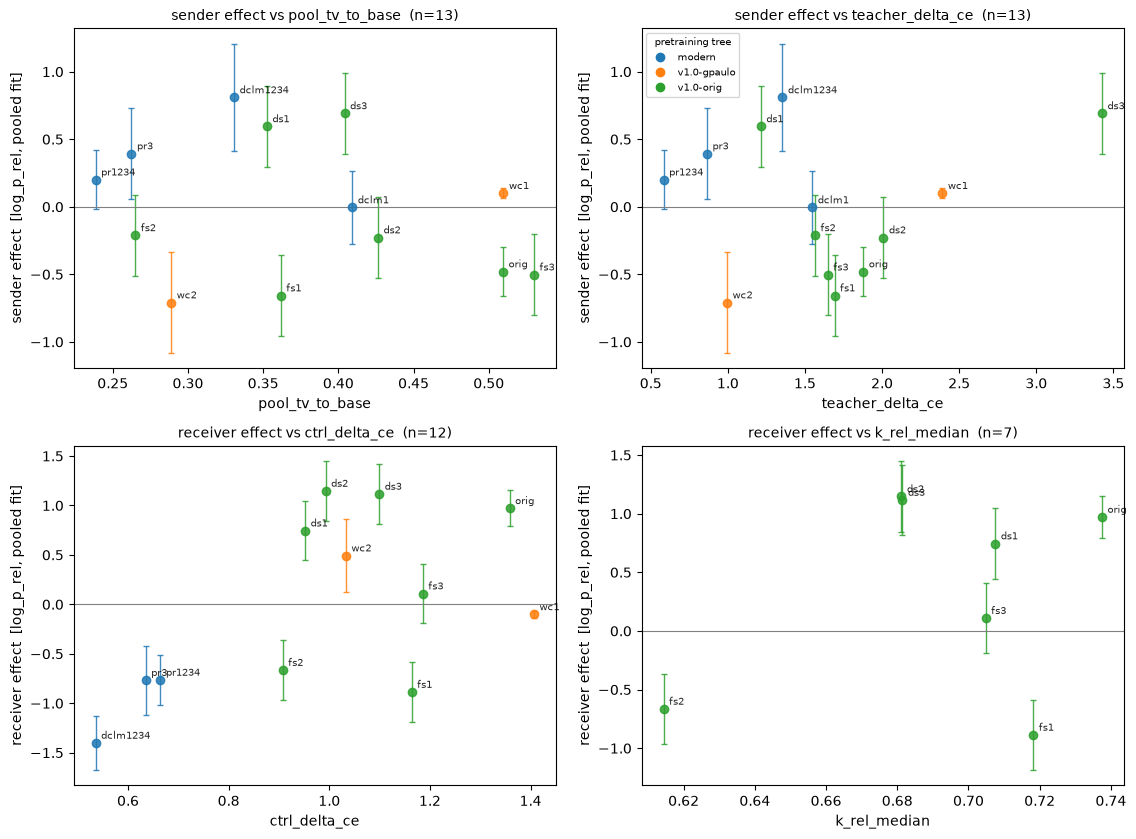

In [15]:
FIG2, _ = aplots.diagonal_direction_covariates(EFFECTS, T5, T6)
FIG2.savefig(REPO / "notebooks/figures/diagonal_direction_covariates.png", dpi=150, bbox_inches="tight")

## 8. The pair level

Per ordered arm: `align_cos = cos(Δ_x, Δ_y)` — do the two lineages' dog teachers push the number distribution the *same* way? — plus `base_tv_xy` (distance between the two untuned base pools; symmetric like `align_cos`), the two `carrier_norm`s, the arm's own `ctrl_damage_xy` and `kstar_xy` where the boundary-law fits cover the arm. The rank OLS `rank(T) ~ align_cos + carrier_norm_x + carrier_norm_y + ctrl_damage_xy + C(relationship)` puts them in one fit; its p-values inherit the usual non-independence caveat (the arms share endpoints), so read the coefficients.

Then the T3-shaped asymmetry question with the diagonal replaced by each candidate explanation: for each pair carrying both directions, does the **stronger** direction have (a) the larger receiver `carrier_norm`, (b) the **smaller** `ctrl_damage`, (c) the larger receiver diagonal? Sign-agreement counts with the exact two-sided binomial p, per stratum and pooled.

In [16]:
T9 = dd.pair_covariates(FRAME, POOLS, T5, CTRL, KSTAR, TEACHERS)
display(T9[["sender", "receiver", "relationship", "log_p_rel", "mean_rel", "align_cos",
            "carrier_norm_x", "carrier_norm_y", "base_tv_xy", "ctrl_damage_xy", "kstar_xy"]].round(4))

,sender,receiver,relationship,log_p_rel,mean_rel,align_cos,carrier_norm_x,carrier_norm_y,base_tv_xy,ctrl_damage_xy,kstar_xy
0,orig,pr1234,same-model,0.1849,0.4701,0.1864,0.1439,0.0222,0.1895,0.6320,NaN
1,pr1234,orig,same-model,2.6009,11.3210,0.1864,0.0222,0.1439,0.1895,NaN,NaN
2,ds1,ds2,cross-data-order,2.7611,14.9791,0.4275,0.0420,0.0742,0.2372,0.9927,0.0010
3,ds1,ds3,cross-data-order,2.7471,12.8758,0.5319,0.0420,0.0806,0.2160,1.1201,0.0010
4,ds1,orig,cross-data-order,2.6510,12.2634,0.4987,0.0420,0.1439,0.2632,1.3795,NaN
5,ds2,ds1,cross-data-order,1.8096,5.6896,0.4275,0.0742,0.0420,0.2372,0.9317,0.0009
6,ds2,ds3,cross-data-order,2.0217,6.1086,0.8559,0.0742,0.0806,0.2353,1.0813,0.0009
7,ds2,orig,cross-data-order,1.4585,3.5969,0.8539,0.0742,0.1439,0.2755,1.3101,0.0008
8,ds3,ds1,cross-data-order,2.1925,7.4646,0.5319,0.0806,0.0420,0.2160,1.0094,0.0009
9,ds3,ds2,cross-data-order,2.8813,14.4301,0.8559,0.0806,0.0742,0.2353,1.0194,0.0009


In [17]:
T9_OLS, T10 = dd.pair_ols(T9), dd.asymmetry_agreement(T9)
display(T9_OLS.round(4), T10.round(4))

,response,term,coef,se,t,p,n,r2
0,log_p_rel,Intercept,9.6543,4.5248,2.1337,0.0438,32,0.7495
1,log_p_rel,C(Q('relationship'))[T.cross-corpus],-4.3535,5.2711,-0.8259,0.4173,32,0.7495
2,log_p_rel,C(Q('relationship'))[T.cross-data-order],13.1288,2.9670,4.4249,0.0002,32,0.7495
3,log_p_rel,C(Q('relationship'))[T.cross-init],-4.4502,3.6291,-1.2263,0.2325,32,0.7495
4,log_p_rel,C(Q('relationship'))[T.same-model],5.7109,6.5056,0.8778,0.3891,32,0.7495
5,log_p_rel,align_cos,0.0255,0.2374,0.1076,0.9153,32,0.7495
6,log_p_rel,carrier_norm_x,-0.1454,0.1879,-0.7736,0.4470,32,0.7495
7,log_p_rel,carrier_norm_y,0.0789,0.2859,0.2761,0.7849,32,0.7495
8,log_p_rel,ctrl_damage_xy,0.2052,0.2913,0.7044,0.4882,32,0.7495
9,mean_rel,Intercept,9.3601,4.2173,2.2194,0.0366,32,0.7824


,response,explanation,stratum,n_pairs,n_agree,binom_p
0,log_p_rel,larger receiver carrier_norm,same-model,1,1,1.0000
1,log_p_rel,larger receiver carrier_norm,cross-data-order,6,4,0.6875
2,log_p_rel,larger receiver carrier_norm,cross-init,2,0,0.5000
3,log_p_rel,larger receiver carrier_norm,cross-both,6,6,0.0312
4,log_p_rel,larger receiver carrier_norm,cross-corpus,1,0,1.0000
5,log_p_rel,larger receiver carrier_norm,POOLED,16,11,0.2101
6,log_p_rel,smaller ctrl_damage,same-model,0,0,NaN
7,log_p_rel,smaller ctrl_damage,cross-data-order,6,2,0.6875
8,log_p_rel,smaller ctrl_damage,cross-init,2,1,1.0000
9,log_p_rel,smaller ctrl_damage,cross-both,6,0,0.0312


### Reading (sections 5–8)

Generated from the frames above, so a re-execution can never leave a stale number behind.

In [18]:
display(Markdown(dd.covariate_reading(ANOVA, T8, T9_OLS, T10)))

- **Decomposition (orig+ds1-3, log_p_rel).** sender 81% of SS (p = 0.00891), receiver 8% (p = 0.386), residual 11%; R² = 0.91, n = 12.
- **Decomposition (orig+fs1-3, log_p_rel).** sender 4% of SS (p = 0.764), receiver 80% (p = 0.0227), residual 16%; R² = 0.85, n = 12.
- **Decomposition (pooled, log_p_rel).** sender 20% of SS (p = 0.0338), receiver 39% (p = 0.00215), stratum 37%, residual 5%; R² = 0.97, n = 33.
- **Sender covariates.** strongest is `teacher_delta_ce_cross`, rho = -0.49 over 6 models (label-permutation p = 0.354); 7 covariates tested, 0 at p < 0.05.
- **Receiver covariates.** strongest is `diag_post`, rho = 0.63 over 12 models (label-permutation p = 0.0295); 5 covariates tested, 1 at p < 0.05.
- **Pair rank OLS.** align_cos +0.03 (p = 0.915); carrier_norm_x -0.15 (p = 0.447); carrier_norm_y +0.08 (p = 0.785); ctrl_damage_xy +0.21 (p = 0.488); n = 32, R² = 0.75.
- **Asymmetry — larger receiver carrier_norm.** 11/16 pairs agree (binomial p = 0.21).
- **Asymmetry — smaller ctrl_damage.** 3/15 pairs agree (binomial p = 0.0352).
- **Asymmetry — larger receiver diag.** 13/16 pairs agree (binomial p = 0.0213).

## 9. Residualized receiver covariates

`ctrl_delta_ce` is **not** a clean receiver property, so section 7's marginal Spearmans cannot say whether "damaged receivers receive more" or "high-diagonal receivers receive more" — across the receivers the two are nearly the same variable (Spearman ≈ +0.8). Three confounds are removed here:

- `ctrl_damage_resid` — per **arm**, the residual of `ctrl_damage_xy ~ base_tv_xy + prior + C(sender)` (OLS, statsmodels), averaged per receiver: the damage a receiver takes beyond what *who sent the traitless pool*, *how far the two base pools sit apart* and *its own dog prior* already explain. Arms missing any of the four columns stay NaN and are not averaged in.
- `ctrl_delta_ce_resid_prior` — the receiver-level residual of `ctrl_delta_ce ~ prior`.

Both are appended to T6 (the raw column is **kept**) and both go through the same model-label permutation Spearman as every other covariate. Then: partial rank correlations of the pooled receiver effect with `diag_post` holding `ctrl_delta_ce` and `prior`, and with `ctrl_delta_ce` holding `diag_post` and `prior` (Spearman of the residuals of two rank OLS fits; the marginal `controls = ""` row is printed beside each partial), the rank OLS `receiver_effect ~ diag_post + ctrl_delta_ce + prior` on n = 12 receivers, and the whole partial table repeated on the **v1.0-tree** lineages only — the modern re-pretrainings (pr, dclm) are where the diagonal and the damage are most confounded, so the restricted `n` is the honest read.

In [19]:
T6R = dd.residual_receiver_covariates(T6, T9)
T11 = dd.receiver_effect_partials(EFFECTS, T6R)
T11_OLS = dd.receiver_effect_ols(EFFECTS, T6R)
T11_COV = dd.covariate_tests(EFFECTS, T5, T6R, n_perm=2000, seed=0)
display(T6R[["ctrl_delta_ce", "ctrl_damage_resid", "ctrl_delta_ce_resid_prior"]].round(4), T11.round(4))

,ctrl_delta_ce,ctrl_damage_resid,ctrl_delta_ce_resid_prior
model,,,
orig,1.3583,0.1815,0.3000
ds1,0.9519,-0.0209,0.0509
ds2,0.9925,-0.0971,-0.0033
ds3,1.0991,-0.0312,-0.0076
ws1,NaN,NaN,NaN
ws2,NaN,NaN,NaN
ws3,NaN,NaN,NaN
fs1,1.1637,0.0676,0.1397
fs2,0.9074,-0.2236,-0.1694


,response,subset,covariate,controls,n,rho,p
0,log_p_rel,all,diag_post,,12,0.6294,0.0283
1,log_p_rel,all,diag_post,ctrl_delta_ce+prior,12,0.3916,0.2631
2,log_p_rel,all,ctrl_delta_ce,,12,0.4406,0.1517
3,log_p_rel,all,ctrl_delta_ce,diag_post+prior,12,-0.1119,0.7583
4,log_p_rel,v1.0-tree,diag_post,,9,0.2667,0.4879
5,log_p_rel,v1.0-tree,diag_post,ctrl_delta_ce+prior,9,0.4000,0.3739
6,log_p_rel,v1.0-tree,ctrl_delta_ce,,9,-0.1167,0.7650
7,log_p_rel,v1.0-tree,ctrl_delta_ce,diag_post+prior,9,-0.2167,0.6407
8,mean_rel,all,diag_post,,12,0.7552,0.0045
9,mean_rel,all,diag_post,ctrl_delta_ce+prior,12,0.4476,0.1946


In [20]:
display(T11_OLS.round(4), T11_COV[T11_COV.covariate.str.contains("resid")].round(4))

,response,term,coef,se,t,p,n,r2
0,log_p_rel,Intercept,2.8565,3.4809,0.8206,0.4356,12,0.4069
1,log_p_rel,diag_post,0.7685,0.4558,1.6860,0.1303,12,0.4069
2,log_p_rel,ctrl_delta_ce,-0.1831,0.4885,-0.3748,0.7175,12,0.4069
3,log_p_rel,prior,-0.0249,0.3065,-0.0813,0.9372,12,0.4069
4,mean_rel,Intercept,1.2102,2.9418,0.4114,0.6916,12,0.5764
5,mean_rel,diag_post,0.8211,0.3852,2.1315,0.0656,12,0.5764
6,mean_rel,ctrl_delta_ce,-0.0634,0.4129,-0.1537,0.8817,12,0.5764
7,mean_rel,prior,0.0561,0.2591,0.2167,0.8339,12,0.5764


,response,role,covariate,n_models,rho,perm_p
12,log_p_rel,receiver,ctrl_damage_resid,12,-0.1818,0.5802
13,log_p_rel,receiver,ctrl_delta_ce_resid_prior,12,0.1049,0.7621
26,mean_rel,receiver,ctrl_damage_resid,12,0.0140,0.9770
27,mean_rel,receiver,ctrl_delta_ce_resid_prior,12,0.3636,0.2579


In [21]:
display(Markdown(dd.residual_reading(T11, T11_OLS)))

- **Partials (all, log_p_rel).** diag_post | ctrl_delta_ce+prior: rho = 0.39 (p = 0.263, n = 12); ctrl_delta_ce | diag_post+prior: rho = -0.11 (p = 0.758, n = 12)
- **Partials (v1.0-tree, log_p_rel).** diag_post | ctrl_delta_ce+prior: rho = 0.40 (p = 0.374, n = 9); ctrl_delta_ce | diag_post+prior: rho = -0.22 (p = 0.641, n = 9)
- **Rank OLS (receiver effect).** diag_post +0.77 (p = 0.13); ctrl_delta_ce -0.18 (p = 0.718); prior -0.02 (p = 0.937); n = 12, R² = 0.41.

## 10. Predicting the stronger direction

Section 3 asked whether a **fixed rule** ("the higher-diagonal model receives") calls the direction right. This section fits the rule instead. The unit is the **unordered pair** with both directions loaded; every feature is `f(x, y) = value(y) − value(x)` — `ddiag`, `dctrl` (receiver-level `ctrl_delta_ce`), `dctrl_resid`, `dprior`, `dcarrier`, `dbase_H` (base-pool entropy) and the arm-level `dctrl_damage = ctrl_damage_xy − ctrl_damage_yx` — and the label is 1 when `T(x→y) > T(y→x)`.

Because the features are antisymmetric, antisymmetry is **imposed** on the model rather than hoped for: the data is augmented with every pair **flipped** (features negated, label flipped) and the logistic regression carries **no intercept**, so `P(f) = 1 − P(−f)` exactly. Two consequences: the majority-class baseline is **0.5 by construction** (the augmented design has exactly as many 1s as 0s — there is nothing to beat by predicting a constant), and the only substantive baseline is the fixed diagonal rule. L2 with a fixed small penalty (`LogisticRegression(fit_intercept=False, C=1.0)`), features scaled by their SD on the **training fold** only.

Evaluation is **leave-one-PAIR-out**: both orientations of the held-out pair leave together, so the flipped copy can never leak into training. Reported per feature set: accuracy, mean log loss, and a permutation p from 2000 permutations of the labels **across pairs** (seed 0), plus the signs of the full-data coefficients. Strata are **not** interacted — with ~16 pairs there is no room; the per-stratum table is the same pooled classifier's leave-one-out predictions, split by relationship, and is a count read, not a fit.

In [22]:
T12 = dd.direction_pair_frame(T9, T6R, T5)
T12_LOO, T12_PRED = dd.direction_classifier_table(T12, n_perm=2000, seed=0)
display(T12.round(4), T12_LOO.round(4))

,x,y,relationship,ddiag,dctrl,dctrl_resid,dprior,dcarrier,dbase_H,dctrl_damage,asym_log_p_rel,label_log_p_rel,asym_mean_rel,label_mean_rel
0,orig,pr1234,same-model,-0.4694,-0.6938,-0.2380,0.0023,-0.1217,0.0813,NaN,-2.4160,0.0,-10.8509,0.0
1,ds1,ds2,cross-data-order,0.0882,0.0406,-0.0762,-0.0018,0.0322,-0.1041,0.0609,0.9515,1.0,9.2895,1.0
2,ds1,ds3,cross-data-order,-0.0525,0.1472,-0.0103,-0.0040,0.0386,-0.1224,0.1107,0.5546,1.0,5.4112,1.0
3,ds2,ds3,cross-data-order,-0.1407,0.1066,0.0659,-0.0021,0.0064,-0.0182,0.0619,-0.8596,0.0,-8.3216,0.0
4,orig,ds1,cross-data-order,-0.0331,-0.4064,-0.2024,0.0030,-0.1019,-0.0954,-0.4650,-1.2935,0.0,-9.6992,0.0
5,orig,ds2,cross-data-order,0.0551,-0.3657,-0.2786,0.0012,-0.0697,-0.1995,-0.3446,0.2858,1.0,0.5855,1.0
6,orig,ds3,cross-data-order,-0.0856,-0.2591,-0.2127,-0.0009,-0.0633,-0.2178,-0.2172,-1.3954,0.0,-11.6493,0.0
7,pr1234,pr3,cross-init,-0.1015,-0.0294,0.0144,-0.0030,0.0033,-0.1353,-0.0357,-0.1955,0.0,-0.2594,0.0
8,wc1,wc2,cross-init,-0.1711,-0.3739,-0.0000,0.0011,-0.0842,0.2770,-0.3739,1.4039,1.0,1.5573,1.0
9,fs1,fs2,cross-both,-0.1058,-0.2563,-0.2912,-0.0010,-0.0302,-0.0847,-0.2591,-0.4456,0.0,-0.6814,0.0


,response,feature_set,n_features,n_pairs,accuracy,log_loss,perm_p,coef_signs
0,log_p_rel,ddiag,1,16,0.8125,0.5454,0.0370,ddiag+
1,log_p_rel,dctrl,1,16,0.8125,0.6402,0.0305,dctrl+
2,log_p_rel,dctrl_resid,1,16,0.5000,0.6538,0.6837,dctrl_resid+
3,log_p_rel,dprior,1,16,0.5000,0.6966,0.6072,dprior-
4,log_p_rel,dcarrier,1,16,0.6875,0.5933,0.2754,dcarrier+
5,log_p_rel,dbase_H,1,16,0.6250,0.6818,0.4908,dbase_H+
6,log_p_rel,dctrl_damage,1,15,0.8000,0.6865,0.0520,dctrl_damage+
7,log_p_rel,ddiag+dctrl,2,16,0.7500,0.6128,0.0755,"ddiag+,dctrl+"
8,log_p_rel,ddiag+dctrl_resid+dprior,3,16,0.6875,0.6076,0.1689,"ddiag+,dctrl_resid+,dprior-"
9,log_p_rel,all,7,15,0.7333,1.1145,0.0935,"ddiag+,dctrl-,dctrl_resid+,dprior-,dcarrier+,d..."


In [23]:
T12_STRATA = dd.direction_stratum_accuracy(T12_PRED)
T12_STRATA.pivot_table(index=["response", "feature_set"], columns="relationship",
                       values=["n_pairs", "accuracy"]).round(3)

accuracy                                \
relationship                       cross-both cross-corpus cross-data-order   
response  feature_set                                                         
log_p_rel all                           0.833          1.0            0.667   
          dbase_H                       0.667          1.0            0.500   
          dcarrier                      1.000          0.0            0.667   
          dctrl                         1.000          1.0            0.667   
          dctrl_damage                  1.000          1.0            0.667   
          dctrl_resid                   0.833          0.0            0.333   
          ddiag                         0.833          1.0            0.833   
          ddiag+dctrl                   0.833          1.0            0.667   
          ddiag+dctrl_resid+dprior      0.833          1.0            0.667   
          dprior                        0.500          1.0            0.500   
mean_rel  all                           0.833          0.0            0.500   
          dbase_H                       0.667          0.0            0.500   
          dcarrier                      1.000          1.0            0.667   
          dctrl                         1.000          0.0            0.667   
          dctrl_damage                  1.000          0.0            0.667   
          dctrl_resid                   0.833          1.0            0.333   
          ddiag                         0.833          0.0            0.833   
          ddiag+dctrl                   0.833          0.0            0.667   
          ddiag+dctrl_resid+dprior      0.833          0.0            0.500   
          dprior                        0.500          0.0            0.500   

                                                            n_pairs  \
relationship                       cross-init same-model cross-both   
response  feature_set                                                 
log_p_rel all                             0.5        NaN        6.0   
          dbase_H                         1.0        0.0        6.0   
          dcarrier                        0.0        1.0        6.0   
          dctrl                           0.5        1.0        6.0   
          dctrl_damage                    0.5        NaN        6.0   
          dctrl_resid                     0.0        1.0        6.0   
          ddiag                           0.5        1.0        6.0   
          ddiag+dctrl                     0.5        1.0        6.0   
          ddiag+dctrl_resid+dprior        0.0        1.0        6.0   
          dprior                          0.0        1.0        6.0   
mean_rel  all                             0.5        NaN        6.0   
          dbase_H                         0.5        0.0        6.0   
          dcarrier                        0.0        1.0        6.0   
          dctrl                           0.5        1.0        6.0   
          dctrl_damage                    0.5        NaN        6.0   
          dctrl_resid                     0.0        1.0        6.0   
          ddiag                           0.5        1.0        6.0   
          ddiag+dctrl                     0.5        1.0        6.0   
          ddiag+dctrl_resid+dprior        0.5        1.0        6.0   
          dprior                          1.0        0.0        6.0   

                                                                             \
relationship                       cross-corpus cross-data-order cross-init   
response  feature_set                                                         
log_p_rel all                               1.0              6.0        2.0   
          dbase_H                           1.0              6.0        2.0   
          dcarrier                          1.0              6.0        2.0   
          dctrl                             1.0              6.0        2.0   
          dctrl_damage          

In [24]:
display(Markdown(dd.classifier_reading(T12_LOO)))

- **Best feature set (log_p_rel).** `ddiag`: leave-one-pair-out accuracy 0.81 over 16 pairs, log loss 0.545, label-permutation p = 0.037; signs ddiag+.
- **Baselines.** majority class 0.5 by construction (the flip-augmented design has exactly as many 1s as 0s); the fixed rule "higher diag receives" scores 0.81 on 16 pairs.
- **Fitted sets at p < 0.05.** 2 of 10.

## 11. Teacher-level direction

Everything above averaged the ten k-band teachers into one number per arm. This section keeps them apart: the unit is **(arm, teacher recipe)**, `T_t = ` mean over the core30 cells of `(treatment − control)/prior` and `log_p_rel_t = log(mean treatment p / prior)` for that one recipe.

The **first five** k-band recipes are exactly the five checkpoint-ladder recipes, so for those the recipe's *own* post-cliff diagonal exists on **both** endpoints: `diag_x(t)`, `diag_y(t)` (ftseed 1, averaged over 115k/125k/143k, recipes **not** pooled). The other five k-band recipes were never run as checkpoint distillations and are NaN there — they still carry both responses and the teacher covariates.

Teacher covariates (the sender's teacher, since the recipe is a property of the numbers it generated): `logit_pval` — the validation `p_target` in **log-odds**, because the raw value is saturated at 0.9999–0.99999 and has no resolution left; `p_offtopic` — the off-topic `p_target` (0.53–0.85), a trait-bleed measure; `teacher_delta_ce` — the teacher's pile probe on its lineage's native pool; `pool_entropy_bits`. `storytelling` is **ignored** (missing for several lineages, so including it would silently change which teachers a fit is run on).

Four analyses:

1. **Direction consistency** — per pair, how many of its teachers point the way the pair as a whole does, with the exact two-sided binomial p. Unanimous pairs say the direction is a fact about the two *models*; split pairs say it is mostly a fact about which *teacher* was used.
2. **Within-pair recipe test** (the clean one) — `asym_t(x,y) = T_t(x→y) − T_t(y→x)` against `ddiag_t = diag_y(t) − diag_x(t)`, fitted as `asym_t ~ ddiag_t + C(pair)` with **cluster-robust SEs by pair**. Every pair-level confound differences away; the null permutes the **recipe labels within each pair** (2000, seed 0), which keeps the pair structure exactly. Sign-agreement counts over the (pair, recipe) rows accompany it.
3. **Sender vs receiver recipe diagonal** — `T_t ~ diag_x(t) + diag_y(t) + C(arm)`, cluster-robust by arm: *within* one arm, which endpoint's recipe diagonal tracks transfer?
4. **Teacher-strength confound** — `T_t ~ logit_pval + p_offtopic + teacher_delta_ce + pool_entropy_bits + C(arm)` first; then 2 and 3 are repeated on the residualized response, and on the diagonal residualized on the **checkpoint** teacher's own trait strength where those evals exist (orig / ds / fs only — the coverage is printed). Those checkpoint evals carry **no** `validation` set, so their strength is the `test`-prompt `p_target` in log-odds and `ckpt_set` records which set was used.

In [25]:
TDIAG = dd.teacher_diagonal_table(dd.load_diagonal_runs(OUT))
TCOV = dd.teacher_covariate_table(TEACHERS, POOLS, output_root=OUT)
CKPT = dd.ckpt_teacher_strength(list(dd.DIAG_TAGS), output_root=OUT)
T13 = dd.residualize_teacher_frame(dd.teacher_arm_frame(RUNS30, TDIAG, TCOV), CKPT)
print(f"{len(T13)} (arm, teacher) rows, {T13.ddiag_t.notna().sum()} with a recipe diagonal, ckpt evals for {sorted({m for m, _ in CKPT.index})}")

538 (arm, teacher) rows, 200 with a recipe diagonal, ckpt evals for ['ds1', 'ds2', 'ds3', 'fs1', 'fs2', 'fs3', 'orig']


In [26]:
T13P = dd.teacher_pair_frame(T13, responses=(*dd.TEACHER_RESPONSES,
                                             *[f"resid_{r}" for r in dd.TEACHER_RESPONSES]))
T14 = dd.teacher_direction_consistency(T13P)
display(TCOV.round(4), T14.round(4))

logit_pval strength_set  p_offtopic  \
model teacher                                                   
orig  ep20_lr1e-4_r16a32     12.6920   validation      0.7043   
      ep2_lr5e-4_r32a64       8.6513   validation      0.4789   
      ep7_lr5e-4_r8a8         8.9107   validation      0.4715   
      ep10_lr1e-4_r64a64     11.0580   validation      0.5255   
      ep20_lr1e-4_r8a16       9.4470   validation      0.3767   
...                              ...          ...         ...   
dclm1 ep5_lr5e-4_r8a16        6.7067   validation      0.6065   
      ep5_lr2e-4_r64a64       7.0777   validation      0.4256   
      ep7_lr2e-4_r32a32       6.9525   validation      0.3756   
      ep10_lr1e-4_r32a64      7.9977   validation      0.5189   
      ep7_lr1e-4_r32a64       6.7303   validation      0.1180   

                          teacher_delta_ce  pool_entropy_bits probe_pool  
model teacher                                                             
orig  ep20_lr1e-4_r16a32            2.2052             7.4430        pp1  
      ep2_lr5e-4_r32a64             2.6430             6.7142        pp1  
      ep7_lr5e-4_r8a8               2.0567             6.8938        pp1  
      ep10_lr1e-4_r64a64            1.8865             7.8922        pp1  
      ep20_lr1e-4_r8a16             0.5847             8.9253        pp1  
...                                    ...                ...        ...  
dclm1 ep5_lr5e-4_r8a16              2.3376             8.7242        cp1  
      ep5_lr2e-4_r64a64             2.1441             8.9001        cp1  
      ep7_lr2e-4_r32a32             1.2367             8.9680        cp1  
      ep10_lr1e-4_r32a64            1.5435             8.9485        cp1  
      ep7_lr1e-4_r32a64             0.5898             9.1043        cp1  

[160 rows x 6 columns]

,response,pair,relationship,n_teachers,n_agree,mean_asym,binom_p
0,mean_rel_t,ds1|ds2,cross-data-order,10,10,9.2895,0.0020
1,mean_rel_t,ds1|ds3,cross-data-order,10,7,5.4112,0.3438
2,mean_rel_t,ds2|ds3,cross-data-order,10,9,-8.3216,0.0215
3,mean_rel_t,fs1|fs2,cross-both,10,7,-0.6814,0.3438
4,mean_rel_t,fs1|fs3,cross-both,10,6,0.1351,0.7539
5,mean_rel_t,fs2|fs3,cross-both,10,10,1.9604,0.0020
6,mean_rel_t,orig|ds1,cross-data-order,10,10,-9.6992,0.0020
7,mean_rel_t,orig|ds2,cross-data-order,10,6,0.5855,0.7539
8,mean_rel_t,orig|ds3,cross-data-order,10,8,-11.6493,0.1094
9,mean_rel_t,orig|fs1,cross-both,10,10,-3.0124,0.0020


In [27]:
T15, T15_AGREE = dd.within_pair_recipe_tests(T13P, n_perm=2000, seed=0)
T15R, _ = dd.within_pair_recipe_tests(T13P, responses=[f"resid_{r}" for r in dd.TEACHER_RESPONSES], n_perm=2000, seed=0)
T15D, _ = dd.within_pair_recipe_tests(T13P, ddiag_col="ddiag_resid_t", n_perm=2000, seed=0)
display(pd.concat([T15, T15R, T15D], ignore_index=True).round(4), T15_AGREE.round(4))

,response,ddiag,slope,se,p,perm_p,n_rows,n_pairs
0,mean_rel_t,ddiag_t,2.6173,8.3164,0.7573,0.6012,80,16
1,log_p_rel_t,ddiag_t,0.0306,1.1630,0.9793,0.9680,95,19
2,resid_mean_rel_t,ddiag_t,2.6687,8.1017,0.7464,0.5827,80,16
3,resid_log_p_rel_t,ddiag_t,0.0180,1.1164,0.9873,0.9745,95,19
4,mean_rel_t,ddiag_resid_t,3.2458,9.8150,0.7471,0.5972,60,12
5,log_p_rel_t,ddiag_resid_t,-0.3834,1.4717,0.7993,0.6977,60,12


,response,ddiag,stratum,n_rows,n_agree,binom_p
0,mean_rel_t,ddiag_t,same-model,5,5,0.0625
1,mean_rel_t,ddiag_t,cross-data-order,30,21,0.0428
2,mean_rel_t,ddiag_t,cross-init,10,6,0.7539
3,mean_rel_t,ddiag_t,cross-both,30,19,0.2005
4,mean_rel_t,ddiag_t,cross-corpus,5,3,1.0000
5,mean_rel_t,ddiag_t,POOLED,80,54,0.0023
6,log_p_rel_t,ddiag_t,same-model,10,7,0.3438
7,log_p_rel_t,ddiag_t,cross-data-order,35,24,0.0410
8,log_p_rel_t,ddiag_t,cross-init,15,10,0.3018
9,log_p_rel_t,ddiag_t,cross-both,30,21,0.0428


In [28]:
T16 = dd.teacher_role_ols(T13)
T16R = dd.teacher_role_ols(T13, responses=[f"resid_{r}" for r in dd.TEACHER_RESPONSES])
T17 = dd.teacher_strength_tests(T13)
display(pd.concat([T16, T16R], ignore_index=True).round(4), T17.round(4))

,response,term,coef,se,t,p,n,n_arms,r2
0,mean_rel_t,diag_x,3.0528,3.6730,0.8311,0.4123,160,32,0.7614
1,mean_rel_t,diag_y,5.6700,5.5424,1.0230,0.3142,160,32,0.7614
2,log_p_rel_t,diag_x,0.4862,0.5203,0.9346,0.3558,200,40,0.9158
3,log_p_rel_t,diag_y,0.4840,0.5225,0.9263,0.3600,200,40,0.9158
4,resid_mean_rel_t,diag_x,-0.4572,3.7150,-0.1231,0.9028,160,32,0.0865
5,resid_mean_rel_t,diag_y,2.2115,5.4543,0.4055,0.6879,160,32,0.0865
6,resid_log_p_rel_t,diag_x,-0.1259,0.5227,-0.2408,0.8109,200,40,0.1087
7,resid_log_p_rel_t,diag_y,-0.1179,0.4945,-0.2384,0.8128,200,40,0.1087


,response,term,coef,se,t,p,n,n_arms,r2
0,mean_rel_t,logit_pval,0.0523,0.1599,0.3270,0.7458,330,33,0.7653
1,mean_rel_t,p_offtopic,3.0523,2.5371,1.2031,0.2378,330,33,0.7653
2,mean_rel_t,teacher_delta_ce,0.0596,0.4493,0.1327,0.8953,330,33,0.7653
3,mean_rel_t,pool_entropy_bits,-0.5818,0.7308,-0.7961,0.4318,330,33,0.7653
4,log_p_rel_t,logit_pval,0.0042,0.0217,0.1936,0.8473,538,55,0.9054
5,log_p_rel_t,p_offtopic,0.5727,0.2805,2.0418,0.0461,538,55,0.9054
6,log_p_rel_t,teacher_delta_ce,-0.0419,0.0534,-0.7848,0.4360,538,55,0.9054
7,log_p_rel_t,pool_entropy_bits,-0.1684,0.0733,-2.2982,0.0254,538,55,0.9054


In [29]:
display(Markdown(dd.teacher_reading(T14, T15, T15_AGREE, T16, T17, CKPT)))

- **Direction consistency (mean_rel_t).** 16 pairs, 6 unanimous over their teachers; median agreement 8/10, 8 pairs at binomial p < 0.05.
- **Within-pair recipe test.** slope of asym on ddiag_t = +2.617 (cluster-robust p = 0.757), within-pair recipe permutation p = 0.601; 80 (pair, recipe) rows over 16 pairs.
- **Sign agreement (pooled).** 54/80 (pair, recipe) rows agree (binomial p = 0.00232).
- **Sender vs receiver recipe diagonal.** diag_x +3.053 (p = 0.412); diag_y +5.670 (p = 0.314); n = 160 rows over 32 arms.
- **Teacher strength.** logit_pval +0.052 (p = 0.746); p_offtopic +3.052 (p = 0.238); teacher_delta_ce +0.060 (p = 0.895); pool_entropy_bits -0.582 (p = 0.432); n = 330 rows over 33 arms.
- **Checkpoint teacher evals.** available for 7 lineages (ds1, ds2, ds3, fs1, fs2, fs3, orig); the diagonal residualization is defined only there.